In [105]:
import os
import glob
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from pathlib import Path
from matplotlib.colors import LogNorm, Normalize

In [12]:
# original DEGs (all pbs wells pooled together
df_hcd = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/data/DEGs/DEGs_all.csv", index_col=0)

In [53]:
# blacklisted genes from Lukas' analysis
df_blacklisted_genes = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/01_figure/outlier_genes/questionable_genes.csv", index_col=0).index
df_blacklisted_genes

Index(['CCDC159', 'ABHD17A', 'BCAP31', 'CD2BP2', 'APH1A', 'SLCO5A1',
       'ENSG00000280441', 'ABCF3', 'GRK2', 'RN7SKP71',
       ...
       'QARS1', 'ZNF580', 'MAP7D1', 'MT-CO3', 'FTH1', 'ALDOA', 'CENPT',
       'RPS15A', 'EDC4', 'ZFP62'],
      dtype='object', name='gene', length=177)

In [9]:
# new DEGs per pbs well
paths = glob.glob("/Users/soeren.becker/repos/HumanCytokineDict/data/DEGs/DEGs_separate_pbs_wells/DEGs_*_separate_pbs_wells.csv")
print(len(paths))

15


In [10]:
all_df = []
for path_i, path in enumerate(paths):
    df = pd.read_csv(path, index_col=0)
    df.rename({"variable": "gene"}, axis=1, inplace=True)
    celltype = Path(path).stem.replace("_separate_pbs_wells", "").replace("DEGs_", "")
    df.loc[:, "celltype"] = celltype
    all_df.append(df)
df = pd.concat(all_df, axis=0)

In [45]:
threshold_lfc = 0.7
threshold_p = 0.01

df.loc[:, "is_DE"] = (df.log_fc.abs() > threshold_lfc) & (df.adj_p_value < threshold_p)
df_counts = df.groupby(["celltype", "cytokine", "gene"]).is_DE.sum().to_frame().reset_index()

In [46]:
df_hcd = pd.merge(df_hcd, df_counts, how="inner")

In [47]:
df_hcd.head()

,gene,log_fc,logCPM,F,p_value,adj_p_value,contrast,celltype,cytokine,num_donors,median_num_cells_pbs,median_num_cells_cytokine,mean_num_cells_pbs,mean_num_cells_cytokine,min_num_cells_pbs,min_num_cells_cytokine,max_num_cells_pbs,max_num_cells_cytokine,is_DE
0,7SK,-1.048281,7.349055,260.724329,4.250459e-15,1.581383e-11,NaN,CD56-dim_NK,4-1BBL,12,2682.0,394.5,2865.583333,509.75,1037.0,142.0,5253.0,1002.0,2
1,RNU4-2,-1.309034,5.600741,187.592521,2.043786e-13,5.069271e-10,NaN,CD56-dim_NK,4-1BBL,12,2682.0,394.5,2865.583333,509.75,1037.0,142.0,5253.0,1002.0,2
2,HLA-E,-0.305392,9.659544,125.582345,1.803139e-11,2.236192e-08,NaN,CD56-dim_NK,4-1BBL,12,2682.0,394.5,2865.583333,509.75,1037.0,142.0,5253.0,1002.0,0
3,MT-RNR1,-0.266956,13.308420,111.108180,6.738925e-11,7.163478e-08,NaN,CD56-dim_NK,4-1BBL,12,2682.0,394.5,2865.583333,509.75,1037.0,142.0,5253.0,1002.0,0
4,BZW1,0.470983,6.448026,104.006873,1.356131e-10,1.261371e-07,NaN,CD56-dim_NK,4-1BBL,12,2682.0,394.5,2865.583333,509.75,1037.0,142.0,5253.0,1002.0,0


#### consider a gene DE iff it is DE in all 6 pbs wells

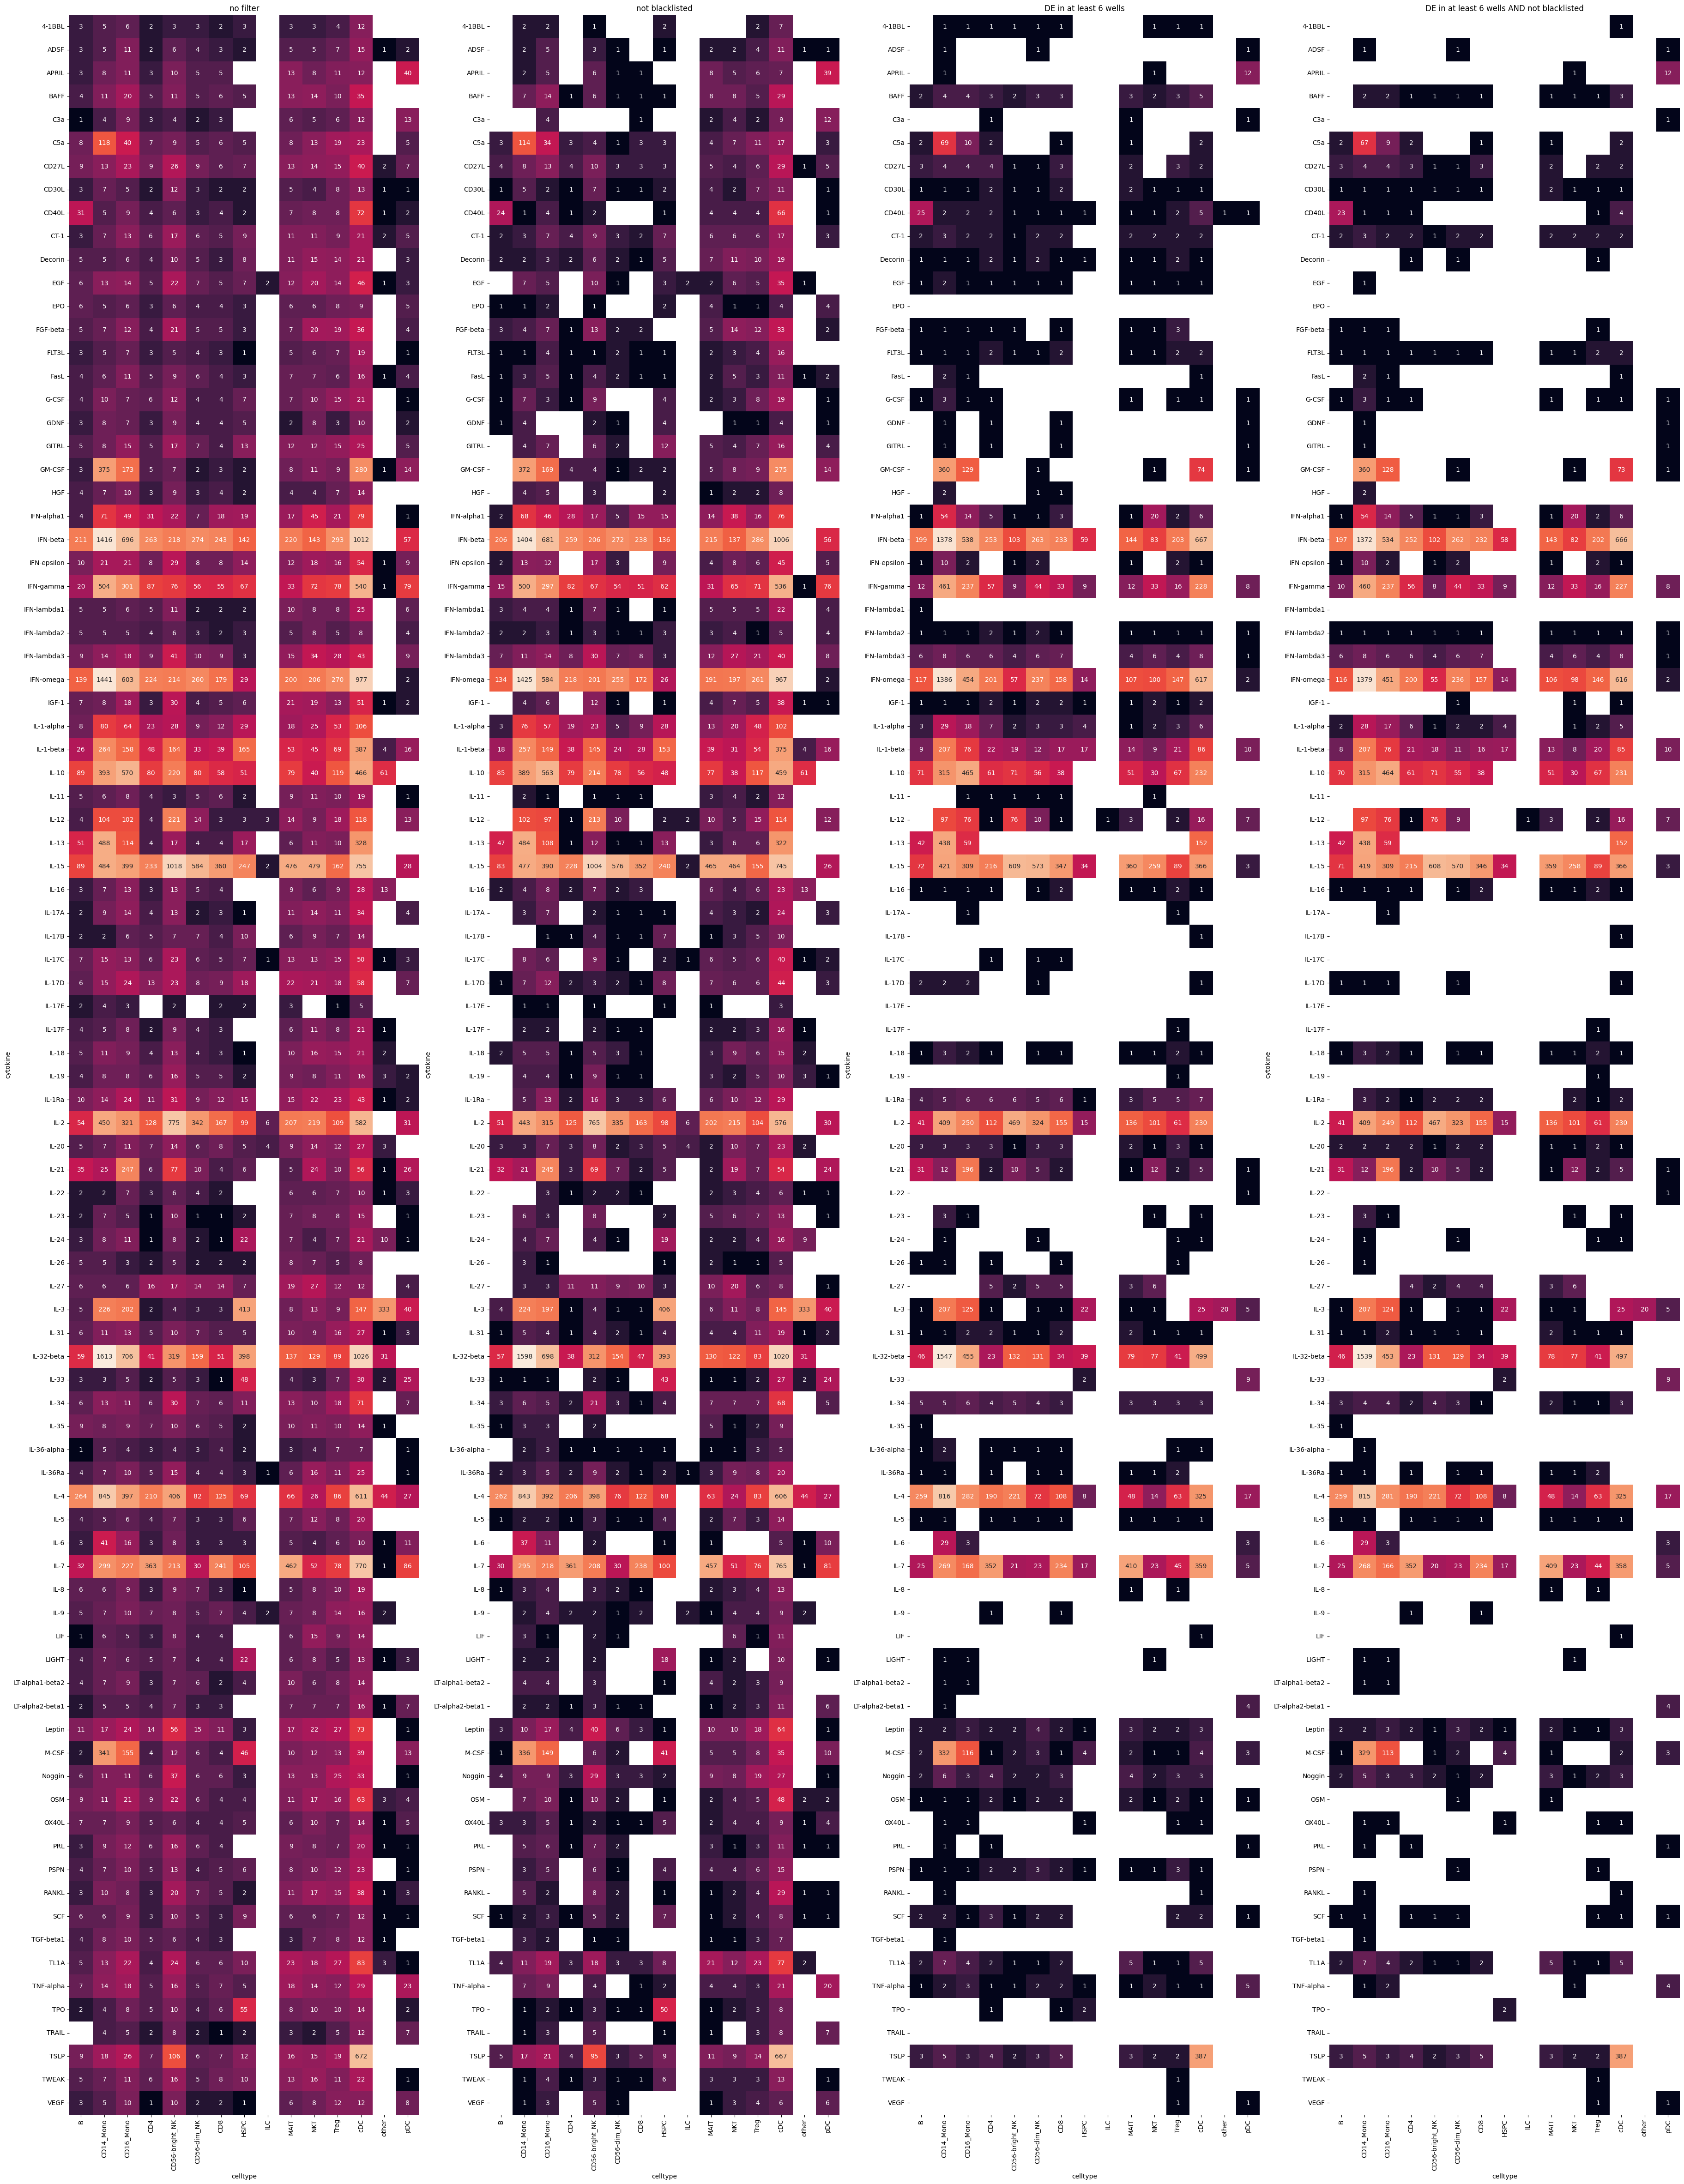

In [95]:
required_de_wells = 6
df_de = df_hcd.loc[
    (
        (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_wo_black = df_hcd.loc[
    (
        (~df_hcd.gene.isin(df_blacklisted_genes)) 
        & (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells = df_hcd.loc[df_hcd.is_DE >= required_de_wells].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells_wo_black = df_hcd.loc[
    (
        (df_hcd.is_DE >= required_de_wells)
        & (~df_hcd.gene.isin(df_blacklisted_genes))
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_pivot = df_de.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)

df_pivot_wo_black = df_de_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_wo_black.index)]
for idx in missing_idcs:
    df_pivot_wo_black.loc[idx, :] = 0
df_pivot_wo_black = df_pivot_wo_black.loc[df_pivot.index]

df_pivot_min_wells = df_de_min_wells.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells.index)]
for idx in missing_idcs:
    df_pivot_min_wells.loc[idx, :] = 0
df_pivot_min_wells = df_pivot_min_wells.loc[df_pivot.index]

df_pivot_min_wells_wo_black = df_de_min_wells_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells_wo_black.index)]
for idx in missing_idcs:
    df_pivot_min_wells_wo_black.loc[idx, :] = 0
df_pivot_min_wells_wo_black = df_pivot_min_wells_wo_black.loc[df_pivot.index]


fig, ax = plt.subplots(1,4,figsize=(45, 80))
shared_kwargs = {
    "cbar_kws": {"shrink": 0.3, "orientation": "horizontal"},
    "square": True,
    "annot": True,
    "fmt": "g",
    "norm": LogNorm(),
    "cbar": False,
}
sns.heatmap(df_pivot, ax=ax[0], **shared_kwargs)
sns.heatmap(df_pivot_wo_black, ax=ax[1], **shared_kwargs)
sns.heatmap(df_pivot_min_wells, ax=ax[2], **shared_kwargs)
sns.heatmap(df_pivot_min_wells_wo_black, ax=ax[3], **shared_kwargs)
ax[0].set_title(f"no filter")
ax[1].set_title(f"not blacklisted")
ax[2].set_title(f"DE in at least {required_de_wells} wells")
ax[3].set_title(f"DE in at least {required_de_wells} wells AND not blacklisted")
plt.show()

#### consider a gene DE iff it is DE in at least 5 pbs wells

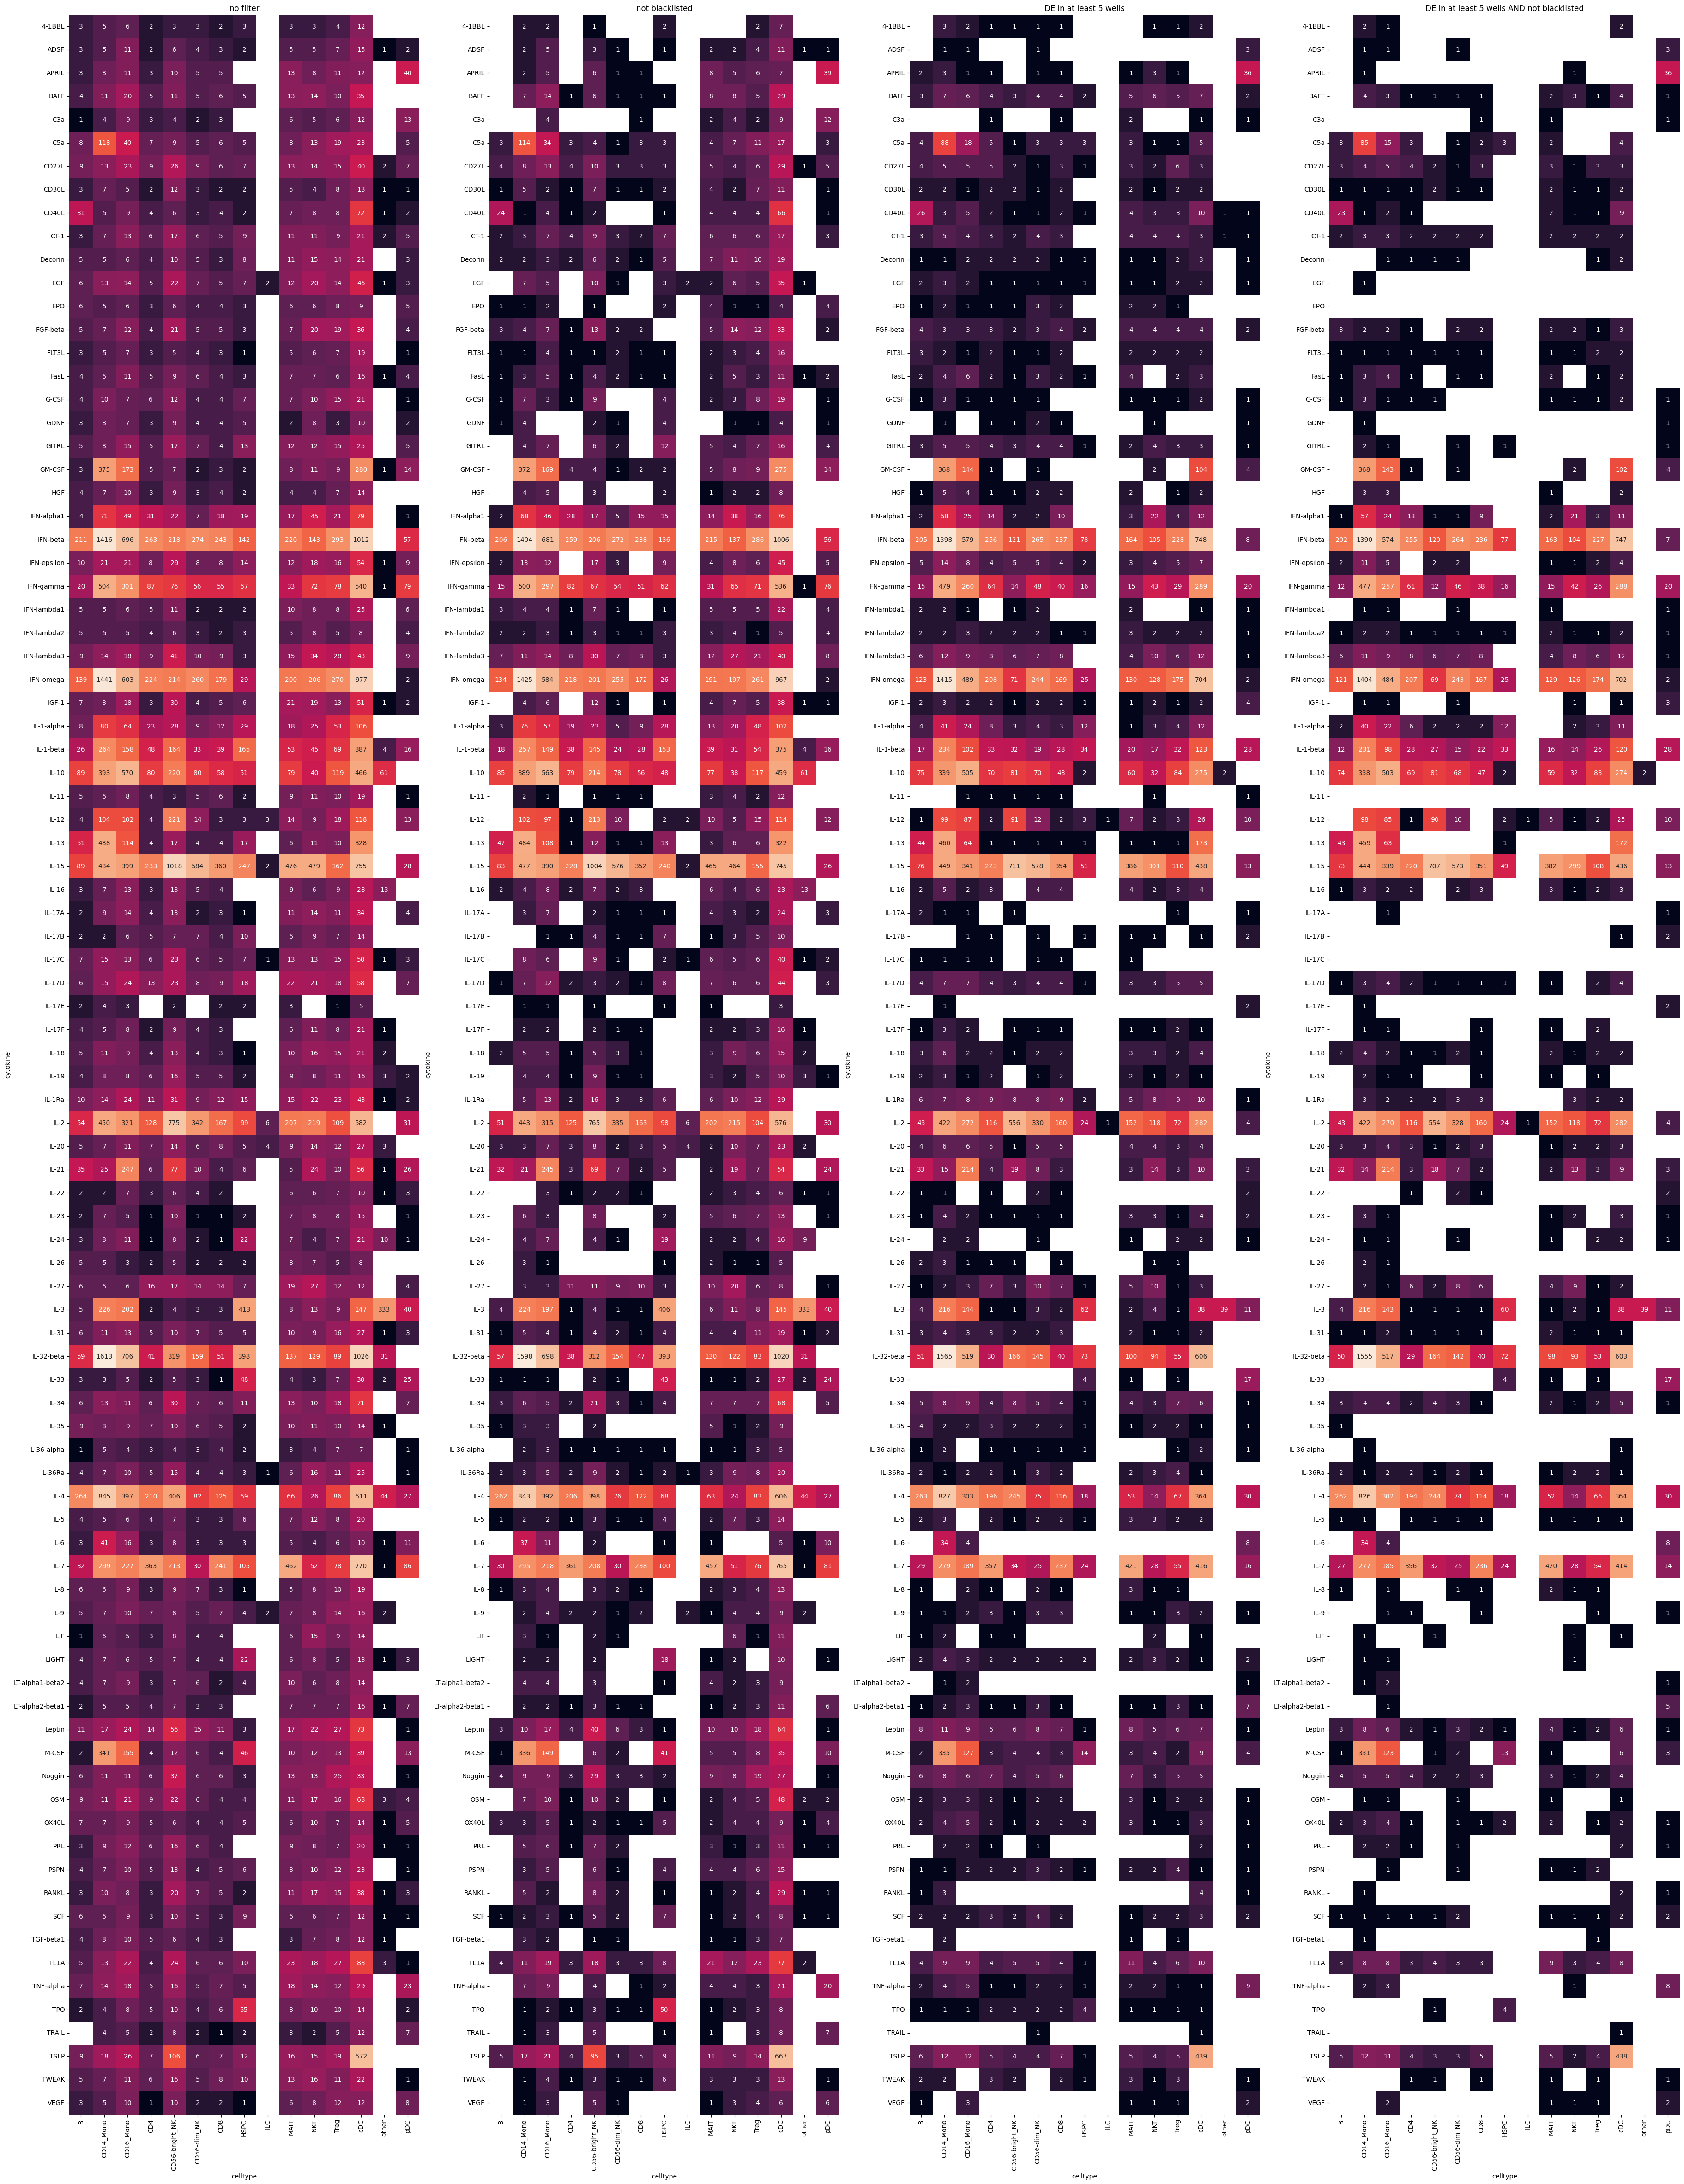

In [96]:
required_de_wells = 5
df_de = df_hcd.loc[
    (
        (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_wo_black = df_hcd.loc[
    (
        (~df_hcd.gene.isin(df_blacklisted_genes)) 
        & (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells = df_hcd.loc[df_hcd.is_DE >= required_de_wells].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells_wo_black = df_hcd.loc[
    (
        (df_hcd.is_DE >= required_de_wells)
        & (~df_hcd.gene.isin(df_blacklisted_genes))
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_pivot = df_de.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)

df_pivot_wo_black = df_de_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_wo_black.index)]
for idx in missing_idcs:
    df_pivot_wo_black.loc[idx, :] = 0
df_pivot_wo_black = df_pivot_wo_black.loc[df_pivot.index]

df_pivot_min_wells = df_de_min_wells.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells.index)]
for idx in missing_idcs:
    df_pivot_min_wells.loc[idx, :] = 0
df_pivot_min_wells = df_pivot_min_wells.loc[df_pivot.index]

df_pivot_min_wells_wo_black = df_de_min_wells_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells_wo_black.index)]
for idx in missing_idcs:
    df_pivot_min_wells_wo_black.loc[idx, :] = 0
df_pivot_min_wells_wo_black = df_pivot_min_wells_wo_black.loc[df_pivot.index]


fig, ax = plt.subplots(1,4,figsize=(45, 80))
shared_kwargs = {
    "cbar_kws": {"shrink": 0.3, "orientation": "horizontal"},
    "square": True,
    "annot": True,
    "fmt": "g",
    "norm": LogNorm(),
    "cbar": False,
}
sns.heatmap(df_pivot, ax=ax[0], **shared_kwargs)
sns.heatmap(df_pivot_wo_black, ax=ax[1], **shared_kwargs)
sns.heatmap(df_pivot_min_wells, ax=ax[2], **shared_kwargs)
sns.heatmap(df_pivot_min_wells_wo_black, ax=ax[3], **shared_kwargs)
ax[0].set_title(f"no filter")
ax[1].set_title(f"not blacklisted")
ax[2].set_title(f"DE in at least {required_de_wells} wells")
ax[3].set_title(f"DE in at least {required_de_wells} wells AND not blacklisted")
plt.show()

#### consider a gene DE iff it is DE in at least 4 pbs wells

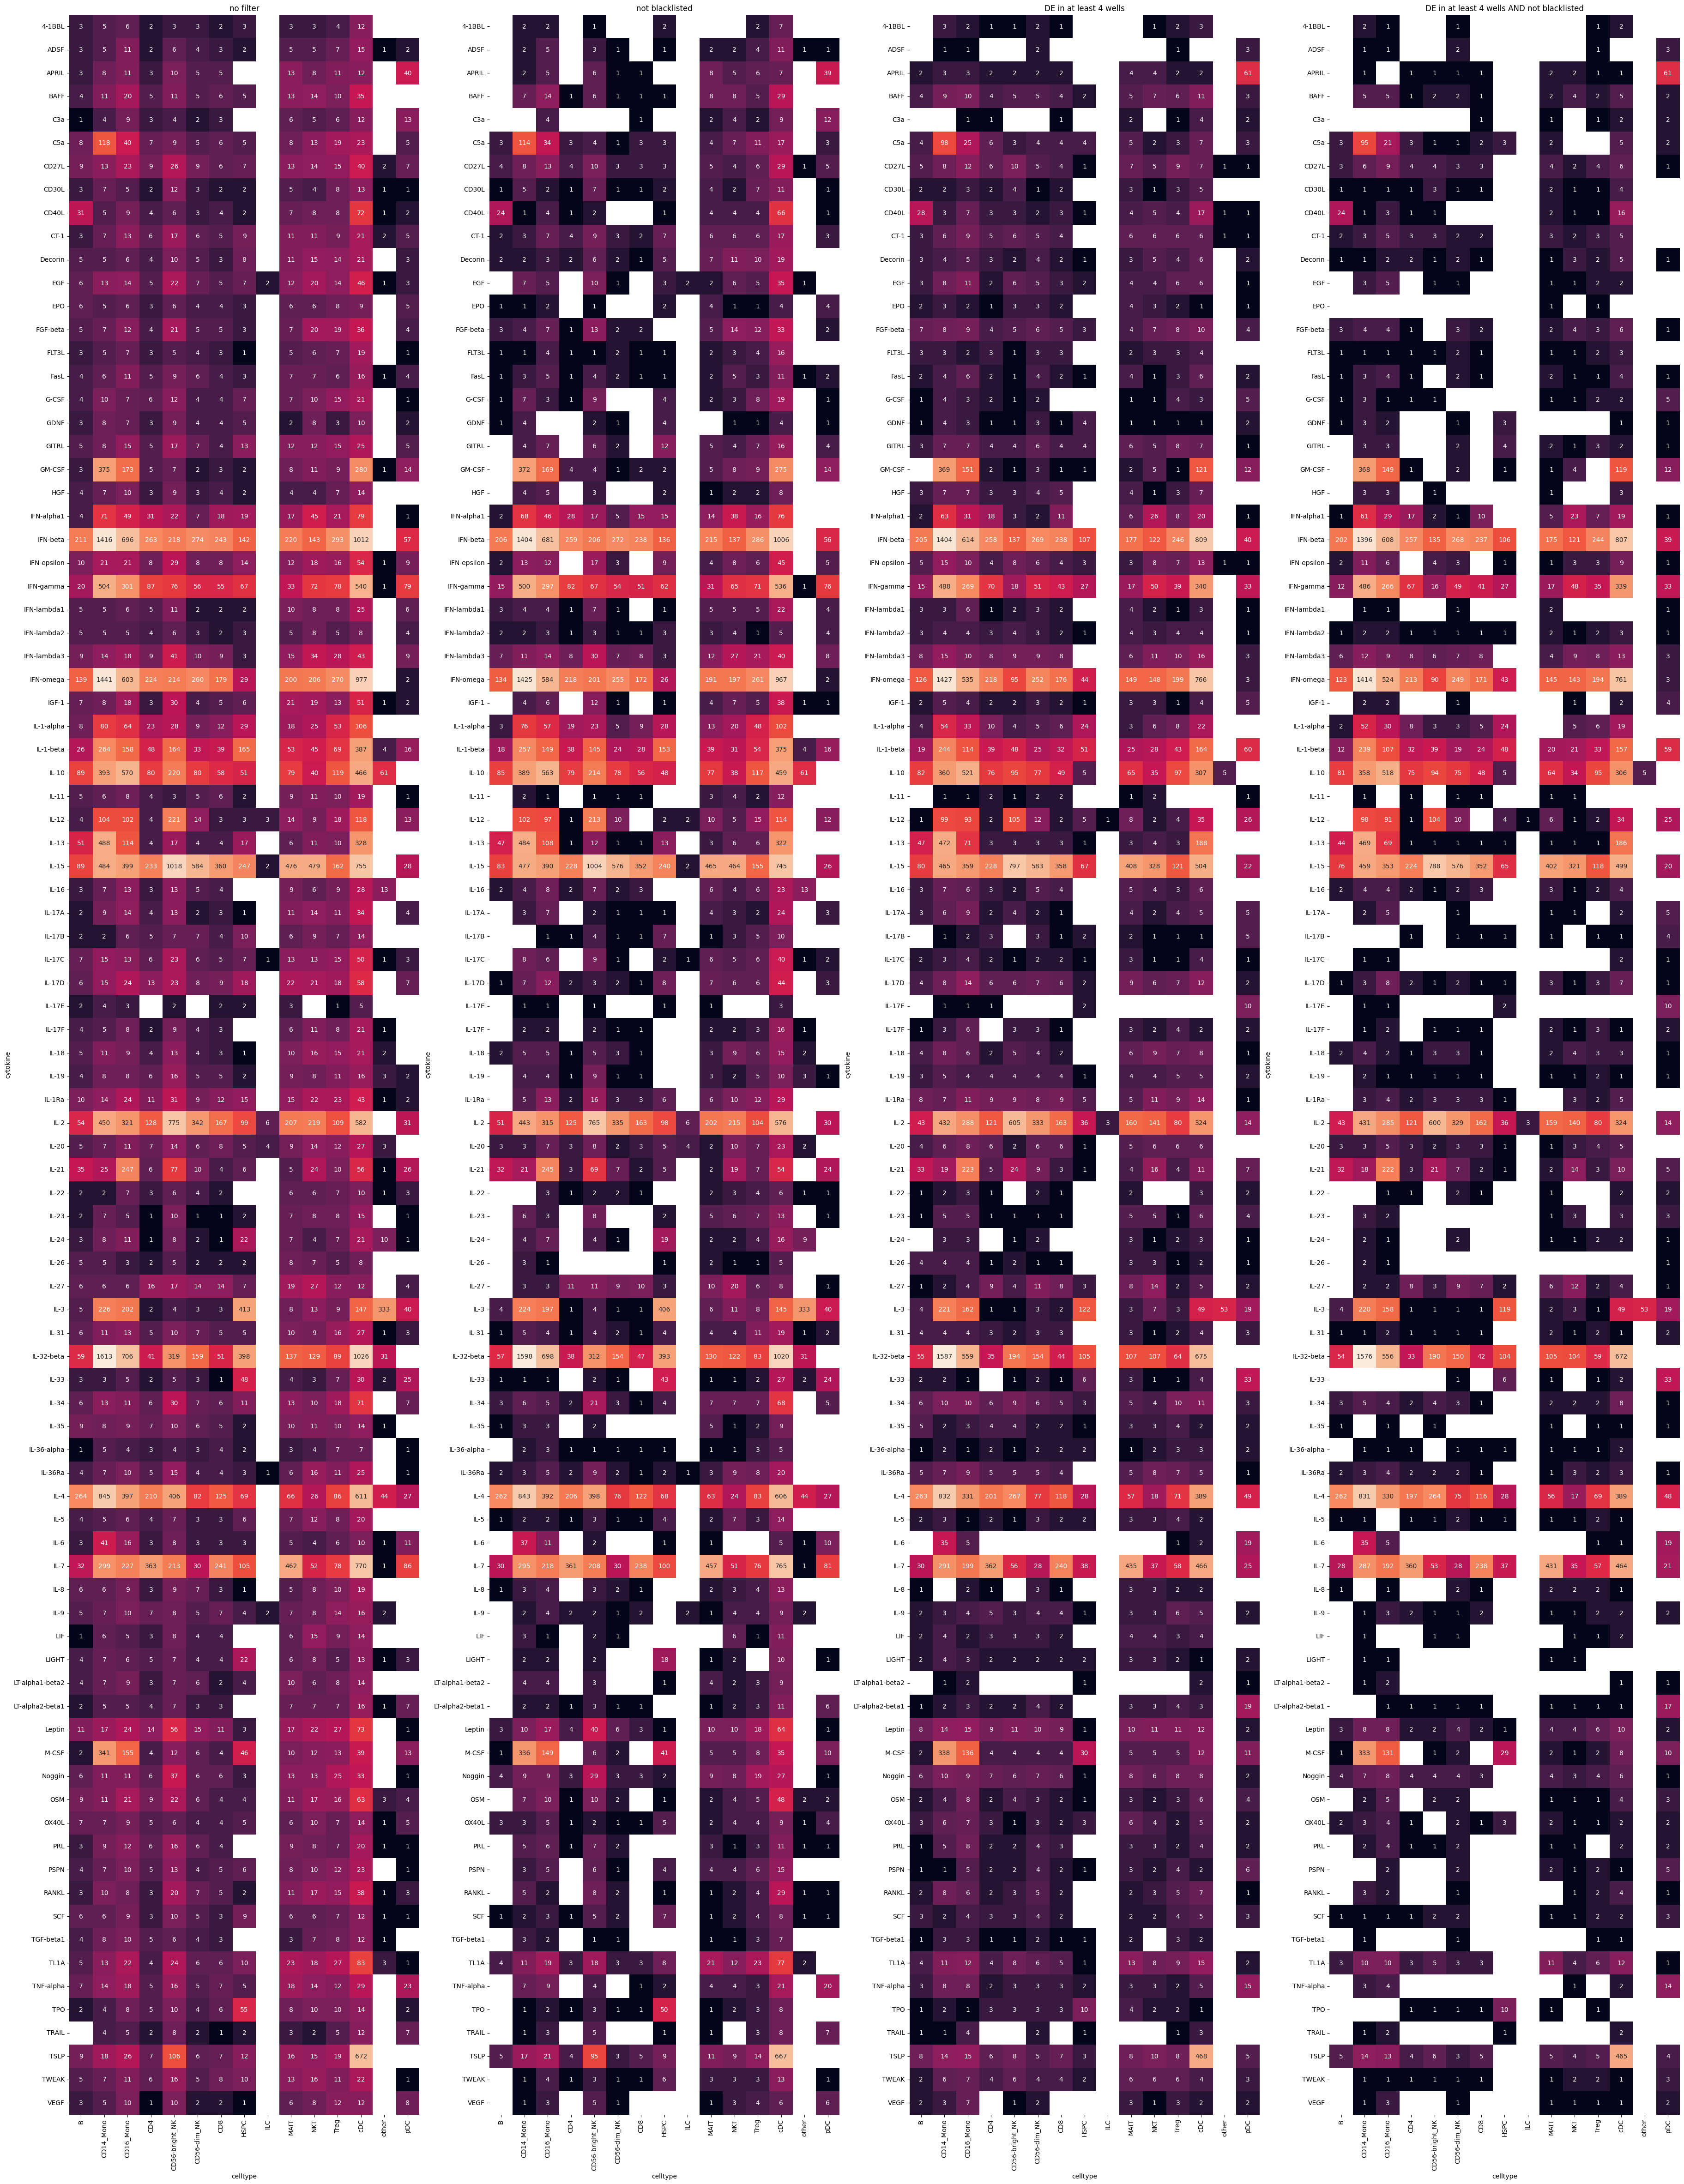

In [97]:
required_de_wells = 4
df_de = df_hcd.loc[
    (
        (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_wo_black = df_hcd.loc[
    (
        (~df_hcd.gene.isin(df_blacklisted_genes)) 
        & (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells = df_hcd.loc[df_hcd.is_DE >= required_de_wells].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells_wo_black = df_hcd.loc[
    (
        (df_hcd.is_DE >= required_de_wells)
        & (~df_hcd.gene.isin(df_blacklisted_genes))
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_pivot = df_de.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)

df_pivot_wo_black = df_de_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_wo_black.index)]
for idx in missing_idcs:
    df_pivot_wo_black.loc[idx, :] = 0
df_pivot_wo_black = df_pivot_wo_black.loc[df_pivot.index]

df_pivot_min_wells = df_de_min_wells.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells.index)]
for idx in missing_idcs:
    df_pivot_min_wells.loc[idx, :] = 0
df_pivot_min_wells = df_pivot_min_wells.loc[df_pivot.index]

df_pivot_min_wells_wo_black = df_de_min_wells_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells_wo_black.index)]
for idx in missing_idcs:
    df_pivot_min_wells_wo_black.loc[idx, :] = 0
df_pivot_min_wells_wo_black = df_pivot_min_wells_wo_black.loc[df_pivot.index]


fig, ax = plt.subplots(1,4,figsize=(45, 80))
shared_kwargs = {
    "cbar_kws": {"shrink": 0.3, "orientation": "horizontal"},
    "square": True,
    "annot": True,
    "fmt": "g",
    "norm": LogNorm(),
    "cbar": False,
}
sns.heatmap(df_pivot, ax=ax[0], **shared_kwargs)
sns.heatmap(df_pivot_wo_black, ax=ax[1], **shared_kwargs)
sns.heatmap(df_pivot_min_wells, ax=ax[2], **shared_kwargs)
sns.heatmap(df_pivot_min_wells_wo_black, ax=ax[3], **shared_kwargs)
ax[0].set_title(f"no filter")
ax[1].set_title(f"not blacklisted")
ax[2].set_title(f"DE in at least {required_de_wells} wells")
ax[3].set_title(f"DE in at least {required_de_wells} wells AND not blacklisted")
plt.show()

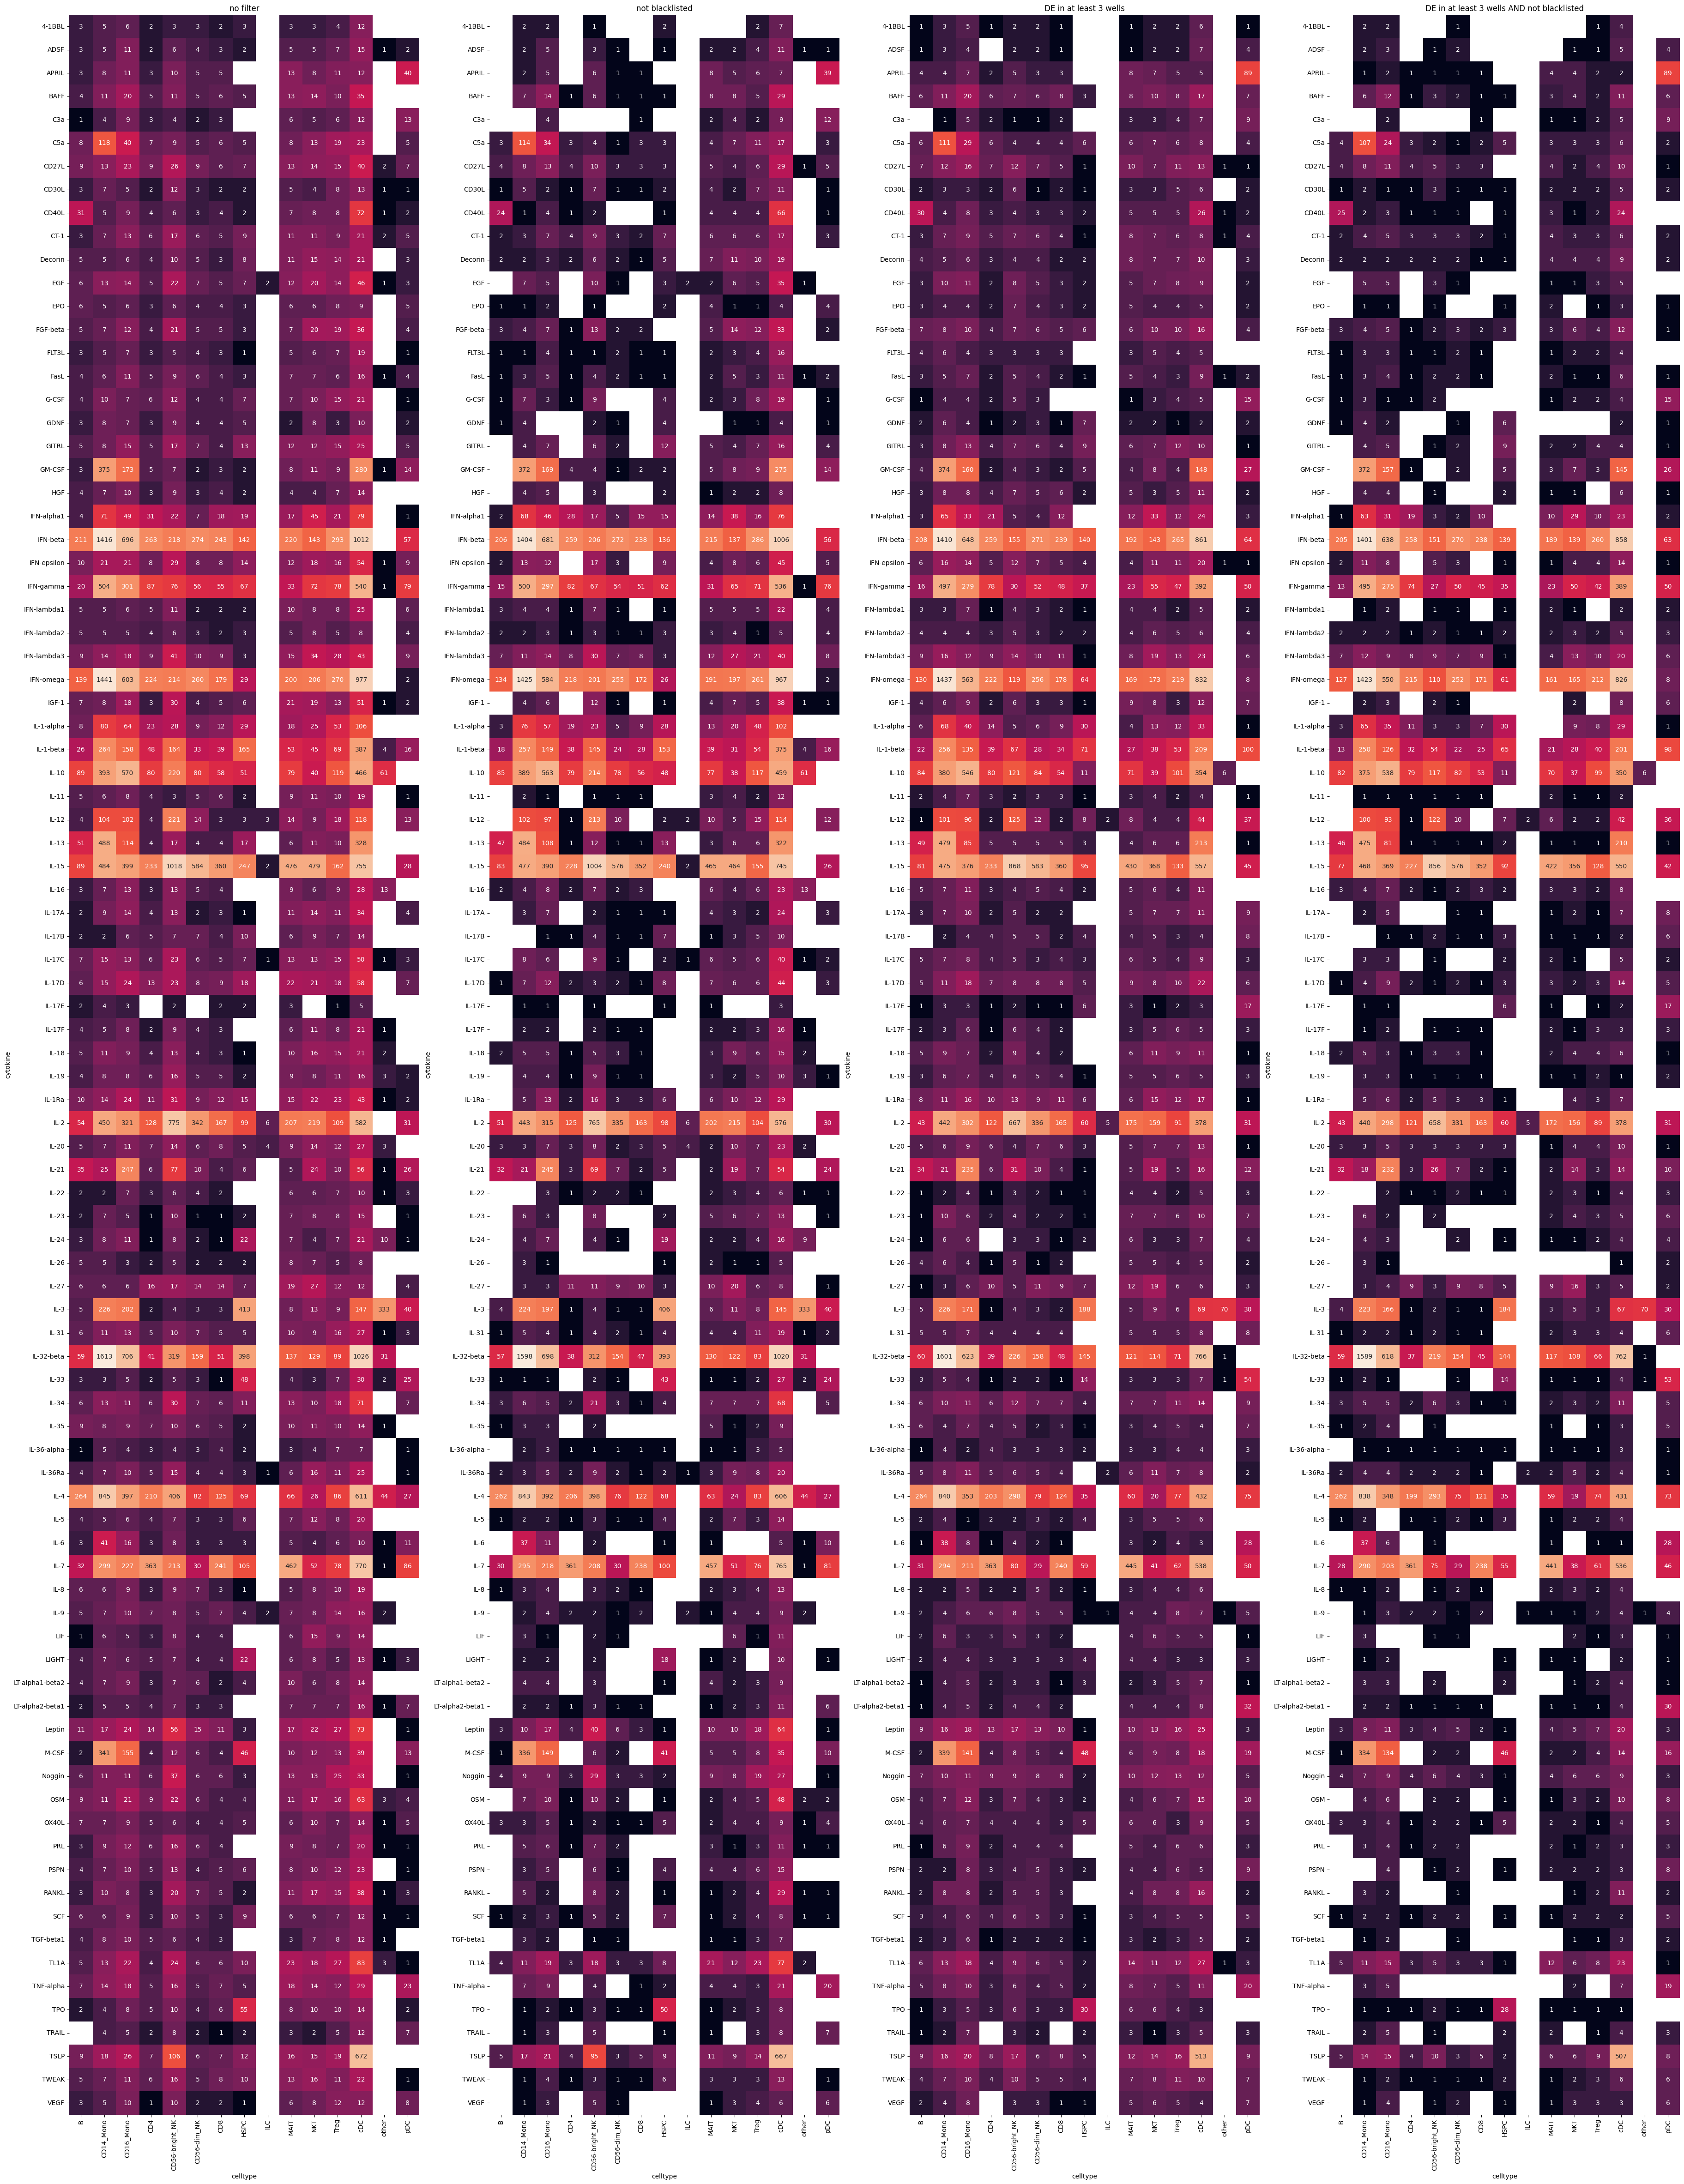

In [98]:
required_de_wells = 3
df_de = df_hcd.loc[
    (
        (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_wo_black = df_hcd.loc[
    (
        (~df_hcd.gene.isin(df_blacklisted_genes)) 
        & (df_hcd.adj_p_value < threshold_p)
        & (df_hcd.log_fc.abs() > threshold_lfc)
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells = df_hcd.loc[df_hcd.is_DE >= required_de_wells].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_de_min_wells_wo_black = df_hcd.loc[
    (
        (df_hcd.is_DE >= required_de_wells)
        & (~df_hcd.gene.isin(df_blacklisted_genes))
    )
].groupby(["celltype", "cytokine"]).gene.nunique().to_frame().reset_index()

df_pivot = df_de.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)

df_pivot_wo_black = df_de_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_wo_black.index)]
for idx in missing_idcs:
    df_pivot_wo_black.loc[idx, :] = 0
df_pivot_wo_black = df_pivot_wo_black.loc[df_pivot.index]

df_pivot_min_wells = df_de_min_wells.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells.index)]
for idx in missing_idcs:
    df_pivot_min_wells.loc[idx, :] = 0
df_pivot_min_wells = df_pivot_min_wells.loc[df_pivot.index]

df_pivot_min_wells_wo_black = df_de_min_wells_wo_black.pivot(
    index="cytokine",
    columns="celltype",
    values="gene"
).fillna(0).astype(int)
missing_idcs = df_pivot.index[~np.isin(df_pivot.index, df_pivot_min_wells_wo_black.index)]
for idx in missing_idcs:
    df_pivot_min_wells_wo_black.loc[idx, :] = 0
df_pivot_min_wells_wo_black = df_pivot_min_wells_wo_black.loc[df_pivot.index]


fig, ax = plt.subplots(1,4,figsize=(45, 80))
shared_kwargs = {
    "cbar_kws": {"shrink": 0.3, "orientation": "horizontal"},
    "square": True,
    "annot": True,
    "fmt": "g",
    "norm": LogNorm(),
    "cbar": False,
}
sns.heatmap(df_pivot, ax=ax[0], **shared_kwargs)
sns.heatmap(df_pivot_wo_black, ax=ax[1], **shared_kwargs)
sns.heatmap(df_pivot_min_wells, ax=ax[2], **shared_kwargs)
sns.heatmap(df_pivot_min_wells_wo_black, ax=ax[3], **shared_kwargs)
ax[0].set_title(f"no filter")
ax[1].set_title(f"not blacklisted")
ax[2].set_title(f"DE in at least {required_de_wells} wells")
ax[3].set_title(f"DE in at least {required_de_wells} wells AND not blacklisted")
plt.show()

#### Overlap of between cytokine signatures (within a cell type)

In [102]:
required_de_wells = 4

df_de_min_wells_wo_black = df_hcd.loc[
    (
        (df_hcd.is_DE >= required_de_wells)
        & (~df_hcd.gene.isin(df_blacklisted_genes))
    )
]

In [103]:
df_de_min_wells_wo_black.head()

,gene,log_fc,logCPM,F,p_value,adj_p_value,contrast,celltype,cytokine,num_donors,median_num_cells_pbs,median_num_cells_cytokine,mean_num_cells_pbs,mean_num_cells_cytokine,min_num_cells_pbs,min_num_cells_cytokine,max_num_cells_pbs,max_num_cells_cytokine,is_DE
18,SCARNA17,-0.625078,4.273774,43.804965,5.009445e-07,1.202428e-04,NaN,CD56-dim_NK,4-1BBL,12,2682.0,394.5,2865.583333,509.750000,1037.0,142.0,5253.0,1002.0,4
7371,KIF5C,1.223421,3.289390,86.953441,4.279071e-09,5.545676e-06,NaN,CD56-dim_NK,ADSF,12,2682.0,441.5,2865.583333,502.916667,1037.0,165.0,5253.0,969.0,6
7449,SCARNA17,-0.467121,4.264327,23.991040,6.781969e-05,4.455115e-03,NaN,CD56-dim_NK,ADSF,12,2682.0,441.5,2865.583333,502.916667,1037.0,165.0,5253.0,969.0,4
15086,SCARNA17,0.748369,4.538208,53.114880,1.044284e-07,2.365304e-05,NaN,CD56-dim_NK,APRIL,12,2682.0,269.0,2865.583333,344.166667,1037.0,94.0,5253.0,1034.0,4
22639,MT-ATP8,-1.267285,5.317684,188.905235,2.677254e-12,2.314932e-09,NaN,CD56-dim_NK,BAFF,12,2682.0,289.0,2865.583333,354.416667,1037.0,94.0,5253.0,814.0,6


In [116]:
df_overlap = pd.DataFrame()

for celltype in tqdm(df_de_min_wells_wo_black.celltype.unique()):

    df_celltype = df_de_min_wells_wo_black.loc[df_de_min_wells_wo_black.celltype == celltype]
    
    for (cytokine_1, cytokine_2) in tqdm(list(itertools.combinations(df_de_min_wells_wo_black.cytokine.unique(), 2)), leave=False):

        signature_1 = df_celltype.loc[df_celltype.cytokine == cytokine_1].gene.values
        signature_2 = df_celltype.loc[df_celltype.cytokine == cytokine_2].gene.values

        overlap = len(np.intersect1d(signature_1, signature_2))

        row_idx = df_overlap.shape[0]
        df_overlap.loc[row_idx, "celltype"] = celltype
        df_overlap.loc[row_idx, "cytokine_1"] = cytokine_1
        df_overlap.loc[row_idx, "cytokine_2"] = cytokine_2
        df_overlap.loc[row_idx, "num_genes_1"] = len(signature_1)
        df_overlap.loc[row_idx, "num_genes_2"] = len(signature_2)
        df_overlap.loc[row_idx, "overlap"] = overlap
        df_overlap.loc[row_idx, "overlap_frac_1"] = (overlap / len(signature_1)) if len(signature_1) > 0 else np.nan
        df_overlap.loc[row_idx, "overlap_frac_2"] = (overlap / len(signature_2)) if len(signature_2) > 0 else np.nan        

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

...

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

  0%|          | 0/4005 [00:00<?, ?it/s]

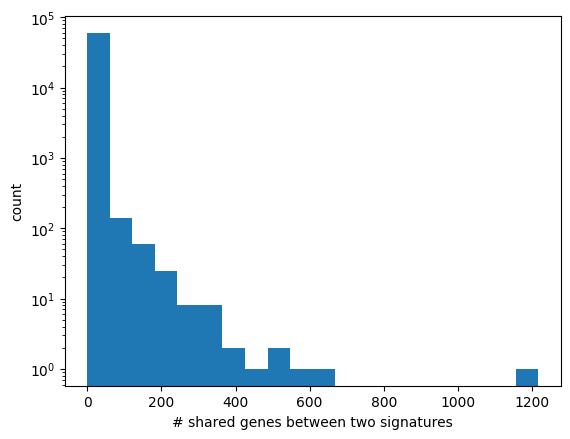

In [136]:
plt.hist(df_overlap.overlap.values, bins=20)
plt.gca().set_yscale('log')
plt.ylabel("count")
plt.xlabel("# shared genes between two signatures")
plt.show()

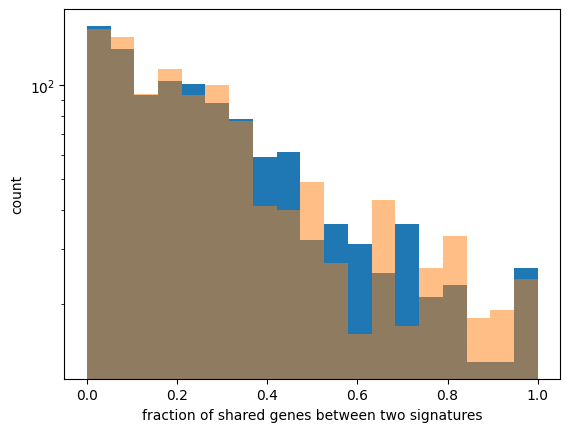

In [137]:
plt.hist(df_overlap.loc[df_overlap.overlap > 3].overlap_frac_1.values, bins=np.linspace(0, 1, 20, endpoint=True))
plt.hist(df_overlap.loc[df_overlap.overlap > 3].overlap_frac_2.values, bins=np.linspace(0, 1, 20, endpoint=True), alpha=0.5)
plt.gca().set_yscale('log')
plt.ylabel("count")
plt.xlabel("fraction of shared genes between two signatures")
plt.show()

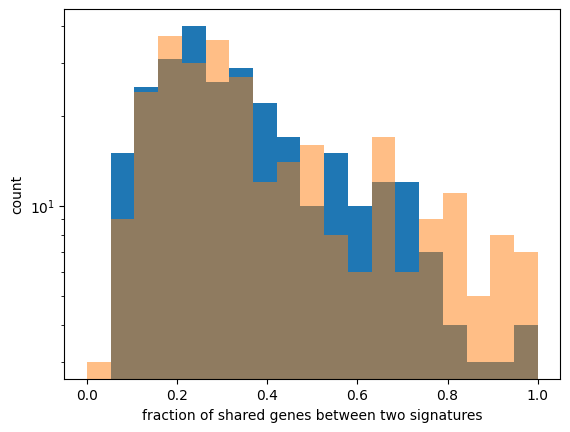

In [138]:
plt.hist(df_overlap.loc[df_overlap.overlap > 50].overlap_frac_1.values, bins=np.linspace(0, 1, 20, endpoint=True))
plt.hist(df_overlap.loc[df_overlap.overlap > 50].overlap_frac_2.values, bins=np.linspace(0, 1, 20, endpoint=True), alpha=0.5)
plt.gca().set_yscale('log')
plt.ylabel("count")
plt.xlabel("fraction of shared genes between two signatures")
plt.show()

In [141]:
df_overlap.loc[(df_overlap.overlap_frac_1 > 0.5) & (df_overlap.overlap > 5)]

,celltype,cytokine_1,cytokine_2,overlap,overlap_frac_1,overlap_frac_2
1382,CD56-dim_NK,IFN-beta,IFN-omega,199.0,0.742537,0.799197
1390,CD56-dim_NK,IFN-beta,IL-15,168.0,0.626866,0.291667
1523,CD56-dim_NK,IFN-gamma,IFN-omega,44.0,0.897959,0.176707
1531,CD56-dim_NK,IFN-gamma,IL-15,38.0,0.775510,0.065972
1540,CD56-dim_NK,IFN-gamma,IL-2,35.0,0.714286,0.106383
...,...,...,...,...,...,...
57601,MAIT,IFN-gamma,IL-15,9.0,0.529412,0.022388
57610,MAIT,IFN-gamma,IL-2,11.0,0.647059,0.069182
58063,MAIT,IL-1-beta,IL-15,14.0,0.700000,0.034826
58387,MAIT,IL-15,IL-7,263.0,0.654229,0.610209


In [142]:
df_overlap.loc[(df_overlap.overlap_frac_1 > 0.5) & (df_overlap.overlap > 5)].celltype.value_counts()

celltype
CD14_Mono         35
CD4               27
CD16_Mono         25
cDC               23
CD8               20
NKT               13
CD56-dim_NK       12
CD56-bright_NK     9
Treg               9
B                  9
HSPC               7
MAIT               7
pDC                2
Name: count, dtype: int64

In [146]:
def func(a, b):
    return "_".join(sorted([a, b]))

df_overlap.loc[:, "cyto_combo"] = df_overlap.apply(lambda x: func(x.cytokine_1, x.cytokine_2), axis=1)

In [148]:
df_overlap.loc[(df_overlap.overlap_frac_1 > 0.6) & (df_overlap.overlap > 5)].cyto_combo.value_counts()

cyto_combo
IFN-gamma_IFN-omega      11
IFN-gamma_IL-15          10
IFN-beta_IFN-omega        9
IL-1-beta_IL-15           9
IFN-alpha1_IFN-beta       6
IFN-gamma_IL-2            6
IFN-alpha1_IFN-omega      6
IL-1-beta_IL-2            5
IL-12_IL-15               5
IFN-alpha1_IL-15          5
IL-2_IL-7                 4
IL-13_IL-4                4
IL-1-alpha_IL-2           4
IL-1-alpha_IL-15          4
IL-1-alpha_IL-7           4
IL-10_IL-15               4
IFN-alpha1_IFN-gamma      3
IL-1-alpha_IL-1-beta      3
IL-15_IL-7                3
IL-27_IL-7                3
IL-21_IL-32-beta          3
IL-12_IL-2                3
IL-15_IL-2                3
IFN-alpha1_IL-10          3
IFN-omega_IL-15           3
IL-1-beta_IL-7            2
IL-12_IL-7                2
IFN-gamma_IL-7            2
IFN-beta_IL-15            2
C5a_M-CSF                 2
GM-CSF_IL-3               1
IFN-alpha1_IL-7           1
IFN-alpha1_IL-2           1
IFN-gamma_IL-4            1
IL-1-alpha_IL-10          1
C5a_IL-21